**WandB training curves without manual CSV download**

Run `wandb login` once before using this notebook.

In [ ]:
from pathlib import Path
import os
import sys

FIGURES_DIR = Path.cwd()
if FIGURES_DIR.name != "figures" and (FIGURES_DIR / "figures").exists():
    FIGURES_DIR = FIGURES_DIR / "figures"
os.chdir(FIGURES_DIR)
sys.path.insert(0, str(FIGURES_DIR))

import importlib
import wandb_training_curves
importlib.reload(wandb_training_curves)

from wandb_training_curves import (
    DEFAULT_ENTITY,
    build_plot_config,
    fetch_wandb_training_curves,
    plot,
    print_performance_table,
    plot_final_distribution,
    plot_horizontal_legend
)

ENTITY = DEFAULT_ENTITY

**SMAX**

Use `condition=None` for vanilla SMAX runs. Vanilla is fetched with the map token included and any run containing `tar_w` excluded, so target-window runs are not mixed into the vanilla plot.


=== SMAX: 3m, vanilla ===
[collect] pci_mappo  jax_pci_mappo_smax_3m_seed42 (801 points)
[collect] mappo      jax_mappo_smax_3m_seed42 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_3m_seed2 (801 points)
[collect] ippo       jax_ippo_smax_3m_seed42 (801 points)
[collect] mappo      jax_mappo_smax_3m_seed1 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_3m_seed1 (801 points)
[collect] mappo      jax_mappo_smax_3m_seed2 (801 points)
[collect] ippo       jax_ippo_smax_3m_seed1 (801 points)
[collect] ippo       jax_ippo_smax_3m_seed2 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_3m_seed2 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_3m_seed42 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_3m_seed1 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_3m_seed2_nosch (801 points)
[write] wandb_cache\SMAX_3m_vanilla\pci_ippo.csv (4 runs, 801 rows)
[write] wandb_cache\SMAX_3m_vanilla\pci_mappo.csv (3 runs, 801 rows)
[write] wandb_cache\SMAX_3m_vanilla\ippo.csv (3 run

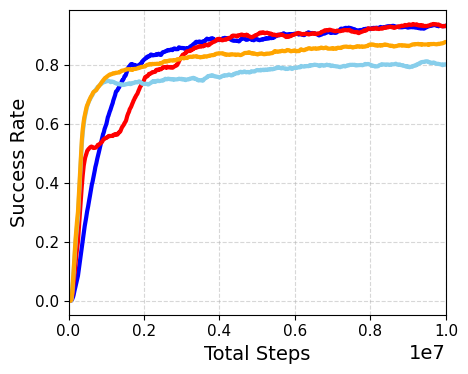

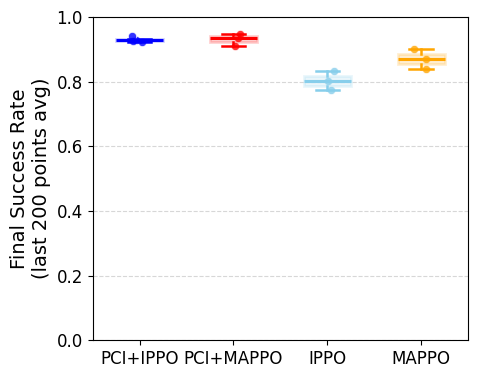


Final Performance Summary (Success Rate)
Based on last 200 points with window_size=20
Algorithm       N     Mean +/- Std    Min      Max     
--------------------------------------------------------------------------------
PCI+IPPO        4     0.930+/-0.007   0.924    0.942   
PCI+MAPPO       3     0.932+/-0.016   0.911    0.949   
IPPO            3     0.803+/-0.024   0.774    0.834   
MAPPO           3     0.870+/-0.025   0.841    0.902   
Note: Values are success rates (0-1 scale)

=== SMAX: 3m, tar_w=2 ===
[collect] pci_ippo   jax_pci_ippo_smax_3m_tar_w=2_seed42 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_3m_tar_w=2_seed2 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_3m_tar_w=2_seed42 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_3m_tar_w=2_seed1 (801 points)
[collect] ippo       jax_ippo_smax_3m_tar_w=2_seed42 (801 points)
[collect] mappo      jax_mappo_smax_3m_tar_w=2_seed42 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_3m_tar_w=2_seed2 (801 points)


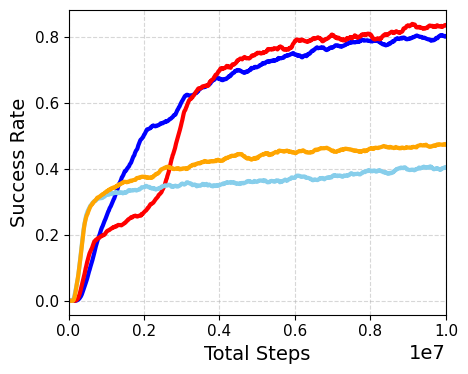

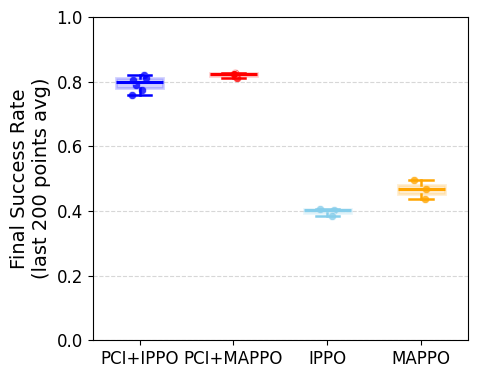


Final Performance Summary (Success Rate)
Based on last 200 points with window_size=20
Algorithm       N     Mean +/- Std    Min      Max     
--------------------------------------------------------------------------------
PCI+IPPO        6     0.794+/-0.022   0.758    0.820   
PCI+MAPPO       3     0.820+/-0.007   0.810    0.826   
IPPO            3     0.398+/-0.009   0.385    0.405   
MAPPO           3     0.467+/-0.023   0.438    0.495   
Note: Values are success rates (0-1 scale)


In [ ]:
from IPython.display import display

SMAX_CASES = [
    {"map": "3m", "condition": None, "label": "vanilla"},
    {"map": "3m", "condition": "tar_w=2", "label": "tar_w=2"},
]
WINDOW = 20
LAST_N = 200

for case in SMAX_CASES:
    smax_map = case["map"]
    condition = case["condition"]
    label = case.get("label") or ("vanilla" if condition is None else condition)
    is_vanilla = condition is None

    smax_filter = [smax_map] if is_vanilla else [smax_map, condition]
    smax_filter = [term for term in smax_filter if term]
    smax_exclude = ["tar_w"] if is_vanilla else []

    filter_parts = [smax_map, label]
    filter_name = "_".join(str(part).replace("=", "") for part in filter_parts if part)
    SMAX_DIR = Path("wandb_cache") / f"SMAX_{filter_name}"

    print(f"\n=== SMAX: {smax_map}, {label} ===")

    fetch_wandb_training_curves(
        preset="smax",
        entity=ENTITY,
        output_dir=SMAX_DIR,
        state="finished",
        contains=smax_filter,
        exclude_contains=smax_exclude,
    )

    smax_config = build_plot_config("smax", SMAX_DIR)

    fig, (ax, _) = plot(
        smax_config,
        figsize=(5, 4),
        window_size=WINDOW,
        xlim=(0, 1e7),
        mean_only=True,
        show=False,
    )
    ax.xaxis.get_label().set_fontsize(14)
    ax.yaxis.get_label().set_fontsize(14)
    ax.title.set_fontsize(15)
    ax.tick_params(axis="both", labelsize=11)
    display(fig)
    
    # 2) final performance distribution
    plot_final_distribution(
        smax_config,
        window_size=WINDOW,
        last_n=LAST_N,
        figsize=(5, 4),
        ylim=(0, 1),
    )

    # 3) summary table
    print_performance_table(
        smax_config,
        window_size=WINDOW,
        last_n=LAST_N,
    )

In [ ]:
from IPython.display import display

SMAX_CASES = [
    {"map": "2s3z", "condition": None, "label": "vanilla"},
    {"map": "2s3z", "condition": "tar_w=4", "label": "tar_w=4"},
    {"map": "2s3z", "condition": "tar_w=3", "label": "tar_w=3"},
]
WINDOW = 20
LAST_N = 200

for case in SMAX_CASES:
    smax_map = case["map"]
    condition = case["condition"]
    label = case.get("label") or ("vanilla" if condition is None else condition)
    is_vanilla = condition is None

    smax_filter = [smax_map] if is_vanilla else [smax_map, condition]
    smax_filter = [term for term in smax_filter if term]
    smax_exclude = ["tar_w"] if is_vanilla else []

    filter_parts = [smax_map, label]
    filter_name = "_".join(str(part).replace("=", "") for part in filter_parts if part)
    SMAX_DIR = Path("wandb_cache") / f"SMAX_{filter_name}"

    print(f"\n=== SMAX: {smax_map}, {label} ===")

    fetch_wandb_training_curves(
        preset="smax",
        entity=ENTITY,
        output_dir=SMAX_DIR,
        state="finished",
        contains=smax_filter,
        exclude_contains=smax_exclude,
    )

    smax_config = build_plot_config("smax", SMAX_DIR)

    fig, (ax, _) = plot(
        smax_config,
        figsize=(5, 4),
        window_size=WINDOW,
        xlim=(0, 1e7),
        mean_only=True,
        show=False,
    )
    ax.xaxis.get_label().set_fontsize(14)
    ax.yaxis.get_label().set_fontsize(14)
    ax.title.set_fontsize(15)
    ax.tick_params(axis="both", labelsize=11)
    display(fig)

    # 2) final performance distribution
    plot_final_distribution(
        smax_config,
        window_size=WINDOW,
        last_n=LAST_N,
        figsize=(5, 4),
        ylim=(0, 1),
    )

    # 3) summary table
    print_performance_table(
        smax_config,
        window_size=WINDOW,
        last_n=LAST_N,
    )

In [ ]:
from IPython.display import display

SMAX_CASES = [
    {"map": "smacv2_5_units", "condition": None, "label": "vanilla"},
    {"map": "smacv2_5_units", "condition": "tar_w=4", "label": "tar_w=4"},
    {"map": "smacv2_5_units", "condition": "tar_w=3", "label": "tar_w=3"},
]
WINDOW = 20
LAST_N = 200

for case in SMAX_CASES:
    smax_map = case["map"]
    condition = case["condition"]
    label = case.get("label") or ("vanilla" if condition is None else condition)
    is_vanilla = condition is None

    smax_filter = [smax_map] if is_vanilla else [smax_map, condition]
    smax_filter = [term for term in smax_filter if term]
    smax_exclude = ["tar_w"] if is_vanilla else []

    filter_parts = [smax_map, label]
    filter_name = "_".join(str(part).replace("=", "") for part in filter_parts if part)
    SMAX_DIR = Path("wandb_cache") / f"SMAX_{filter_name}"

    print(f"\n=== SMAX: {smax_map}, {label} ===")

    fetch_wandb_training_curves(
        preset="smax",
        entity=ENTITY,
        output_dir=SMAX_DIR,
        state="finished",
        contains=smax_filter,
        exclude_contains=smax_exclude,
    )

    smax_config = build_plot_config("smax", SMAX_DIR)

    fig, (ax, _) = plot(
        smax_config,
        figsize=(5, 4),
        window_size=WINDOW,
        xlim=(0, 1e7),
        mean_only=True,
        show=False,
    )
    ax.xaxis.get_label().set_fontsize(14)
    ax.yaxis.get_label().set_fontsize(14)
    ax.title.set_fontsize(15)
    ax.tick_params(axis="both", labelsize=11)
    display(fig)

    # 2) final performance distribution
    plot_final_distribution(
        smax_config,
        window_size=WINDOW,
        last_n=LAST_N,
        figsize=(5, 4),
        ylim=(0, 1),
    )

    # 3) summary table
    print_performance_table(
        smax_config,
        window_size=WINDOW,
        last_n=LAST_N,
    )

**CLI examples**

In [ ]:
# !python wandb_training_curves.py --preset sh --plot --save-png sh_training_curve.png
# !python wandb_training_curves.py --preset sh-noise --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset sh --name-suffix _noise0.1 --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset smax --list-runs --contains 2s3z
# !python wandb_training_curves.py --preset smax --contains 2s3z tar_w=4 --plot --save-png smax_2s3z_tarw4.png